In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score,f1_score 

In [4]:
train_data=fetch_20newsgroups(
    subset="train",
    remove=("headers","footers","quotes")
)

In [5]:
test_data=fetch_20newsgroups(
    subset="test",
    remove=("headers","footers","quotes")
)

In [7]:
#separate x and y
x_train_text=train_data.data
y_train=train_data.target

x_test_text=test_data.data
y_test=test_data.target

class_names=train_data.target_names

In [8]:
print("Taining data: ",len(x_train_text))
print("Testing data: ",len(x_test_text))
print("Number of classes:", len(class_names))

Taining data:  11314
Testing data:  7532
Number of classes: 20


In [10]:
#Model 1 with max features 1000
vect1=CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=1000
)
x_train1=vect1.fit_transform(x_train_text)
x_test1=vect1.transform(x_test_text)

mnb1 =MultinomialNB()
mnb1.fit(x_train1,y_train)
y_pred1=mnb1.predict(x_test1)

acc1=accuracy_score(y_test,y_pred1)

f1_1=f1_score(
    y_test,y_pred1,average="weighted",zero_division=0
)
print("\nModel 1 - Max Features = 1000")
print("Accuracy:", acc1)
print("F1 Score:", f1_1)





Model 1 - Max Features = 1000
Accuracy: 0.4632235793945831
F1 Score: 0.45293282332147855


In [11]:
#Model2 with max featires 3000
vect2=CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=3000
)

x_train2=vect2.fit_transform(x_train_text)
x_test2=vect2.transform(x_test_text)

mnb2=MultinomialNB()
mnb2.fit(x_train2,y_train)
y_pred2=mnb2.predict(x_test2)

acc2=accuracy_score(y_test,y_pred2)

f1_2=f1_score(
    y_test,y_pred2,average="weighted",zero_division=0
)

print("\nModel 2")
print("Accuracy: ",acc2)
print("F1_Score: ",f1_2)


Model 2
Accuracy:  0.5582846521508231
F1_Score:  0.545433674104581


In [12]:
#  Model 3 - Max Features = 5000

vect3 = CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=5000
)

x_train3 = vect3.fit_transform(x_train_text)
x_test3 = vect3.transform(x_test_text)

mnb3 = MultinomialNB()
mnb3.fit(x_train3, y_train)

y_pred3 = mnb3.predict(x_test3)

acc3 = accuracy_score(y_test, y_pred3)

f1_3 = f1_score(
    y_test,
    y_pred3,
    average="weighted",
    zero_division=0
)

print("\nModel 3 - Max Features = 5000")
print("Accuracy:", acc3)
print("F1 Score:", f1_3)



Model 3 - Max Features = 5000
Accuracy: 0.5950610727562401
F1 Score: 0.5806279904954282


In [13]:
#comaparison table
comparison=pd.DataFrame({
     "Max Features": [1000, 3000, 5000],
    "Accuracy": [acc1, acc2, acc3],
    "F1 Score": [f1_1, f1_2, f1_3]
})
print("\nComparison of Models")
print(comparison.round(4))


Comparison of Models
   Max Features  Accuracy  F1 Score
0          1000    0.4632    0.4529
1          3000    0.5583    0.5454
2          5000    0.5951    0.5806


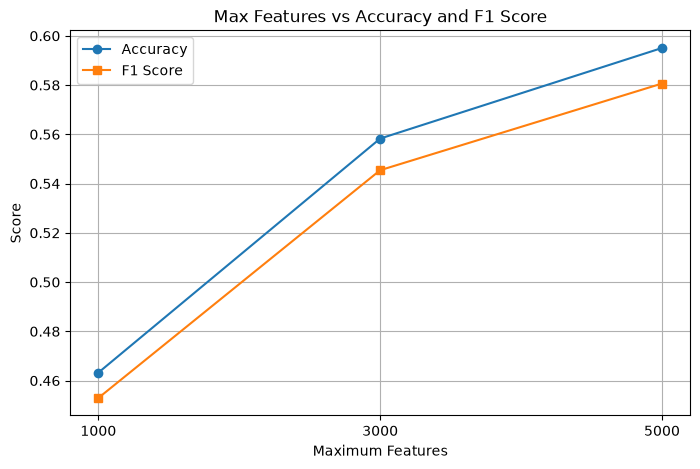

In [15]:
models = ["1000", "3000", "5000"]

accuracy = [acc1, acc2, acc3]
f1_scores = [f1_1, f1_2, f1_3]
plt.figure(figsize=(8,5))

plt.plot(
    models,
    accuracy,
    marker="o",
    label="Accuracy"
)
plt.plot(
    models,
    f1_scores,
    marker="s",
    label="F1 Score"
)

plt.title("Max Features vs Accuracy and F1 Score")
plt.xlabel("Maximum Features")
plt.ylabel("Score")

plt.legend()
plt.grid(True)

plt.show()